In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Dataset.csv to Dataset.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('Dataset.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [ ]:
yearly_releases = (
    df.groupby('release_year')
    .size()
    .reset_index(name='content_count')
)

yearly_releases = yearly_releases.sort_values('release_year')

print("Historical yearly releases:")
display(yearly_releases.head(10))

print("\nMost recent years:")
display(yearly_releases.tail(10))

Historical yearly releases:


,release_year,content_count
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
5,1946,2
6,1947,1
7,1954,2
8,1955,3
9,1956,2



Most recent years:


,release_year,content_count
64,2012,236
65,2013,286
66,2014,352
67,2015,555
68,2016,901
69,2017,1030
70,2018,1146
71,2019,1030
72,2020,953
73,2021,592


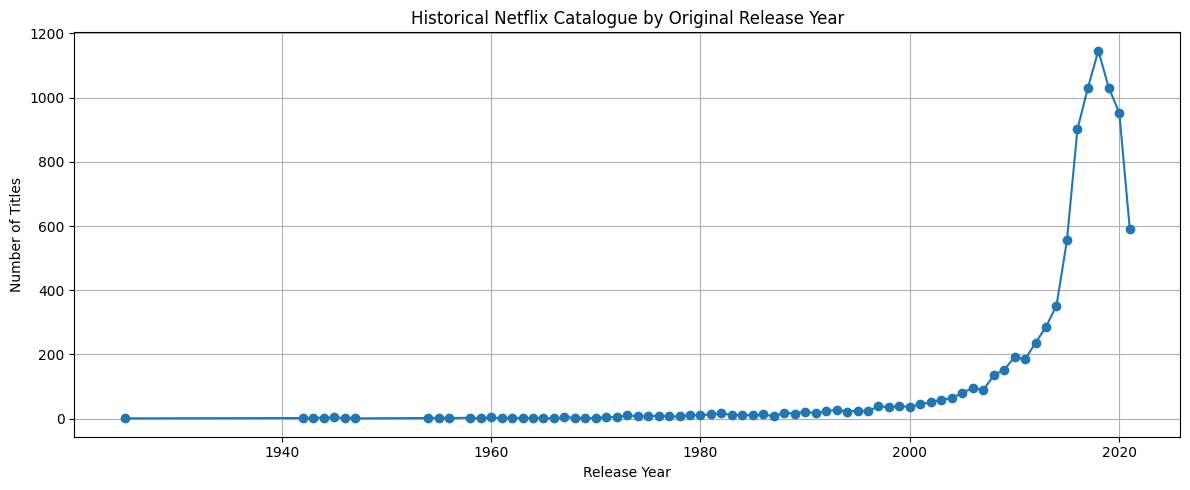

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_releases['release_year'],
    yearly_releases['content_count'],
    marker='o'
)

plt.title('Historical Netflix Catalogue by Original Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
ts = yearly_releases.copy()

ts = ts.sort_values('release_year').reset_index(drop=True)

ts['year_index'] = ts['release_year'] - ts['release_year'].min()
ts['year_squared'] = ts['year_index'] ** 2

print("Forecasting dataset:")
display(ts.head())

Forecasting dataset:


,release_year,content_count,year_index,year_squared
0,1925,1,0,0
1,1942,2,17,289
2,1943,3,18,324
3,1944,3,19,361
4,1945,4,20,400


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

split_index = int(len(ts) * 0.8)

train = ts.iloc[:split_index].copy()
test = ts.iloc[split_index:].copy()

X_train = train[['year_index']]
y_train = train['content_count']

X_test = test[['year_index']]
y_test = test['content_count']

model = LinearRegression()
model.fit(X_train, y_train)

test_predictions = model.predict(X_test)

print("Model trained successfully!")
print("Training years:", train['release_year'].min(), "-", train['release_year'].max())
print("Testing years:", test['release_year'].min(), "-", test['release_year'].max())

Model trained successfully!
Training years: 1925 - 2006
Testing years: 2007 - 2021


In [ ]:
mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
r2 = r2_score(y_test, test_predictions)

print("Forecast Evaluation")
print("-------------------")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Forecast Evaluation
-------------------
MAE: 475.14
RMSE: 603.20
R² Score: -1.5930


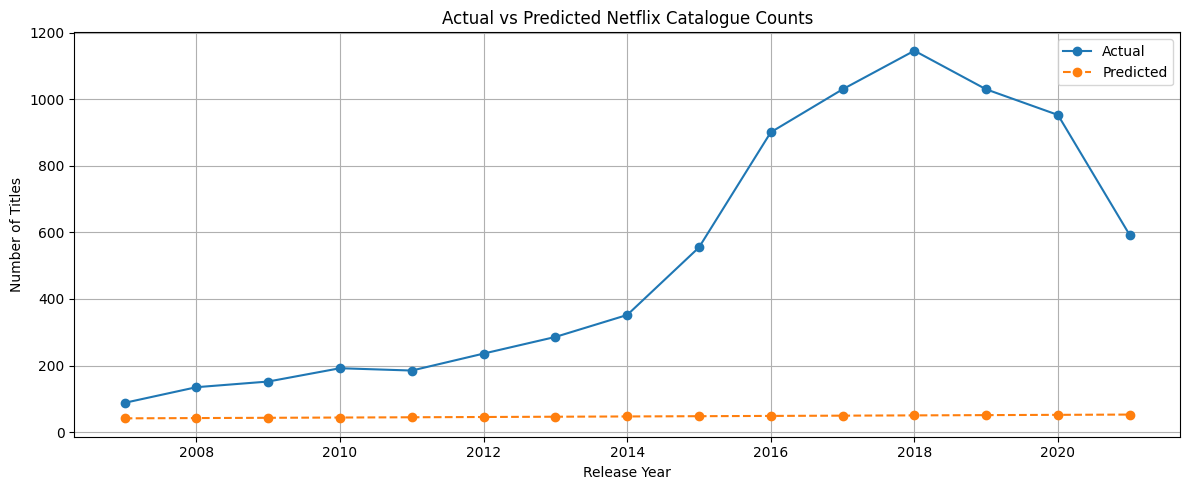

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    test['release_year'],
    y_test,
    marker='o',
    label='Actual'
)

plt.plot(
    test['release_year'],
    test_predictions,
    marker='o',
    linestyle='--',
    label='Predicted'
)

plt.title('Actual vs Predicted Netflix Catalogue Counts')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
last_year = int(ts['release_year'].max())

future_years = np.arange(last_year + 1, last_year + 6)

future_data = pd.DataFrame({
    'release_year': future_years
})

future_data['year_index'] = (
    future_data['release_year'] - ts['release_year'].min()
)

future_predictions = model.predict(future_data[['year_index']])

future_data['predicted_content_count'] = np.maximum(
    0,
    np.round(future_predictions)
).astype(int)

print("Future trend estimates:")
display(future_data)

Future trend estimates:


,release_year,year_index,predicted_content_count
0,2022,97,54
1,2023,98,54
2,2024,99,55
3,2025,100,56
4,2026,101,57


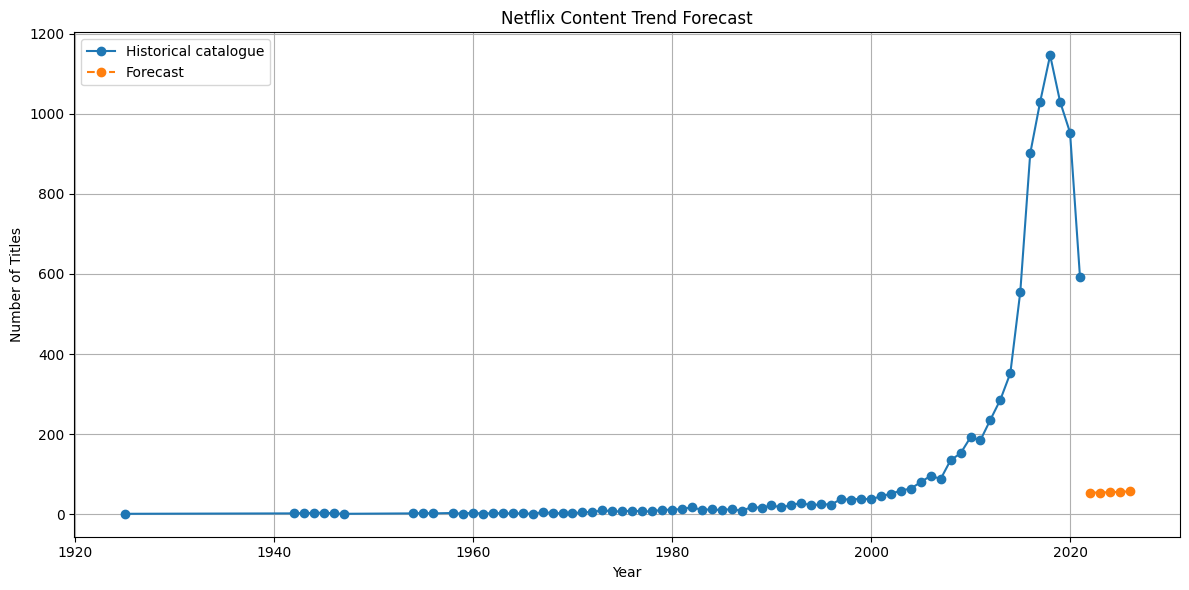

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    ts['release_year'],
    ts['content_count'],
    label='Historical catalogue',
    marker='o'
)

plt.plot(
    future_data['release_year'],
    future_data['predicted_content_count'],
    label='Forecast',
    marker='o',
    linestyle='--'
)

plt.title('Netflix Content Trend Forecast')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig('Netflix_Trend_Forecast.png', dpi=300)
plt.show()

In [ ]:
yearly_releases.to_csv(
    'Netflix_Historical_Releases.csv',
    index=False
)

future_data.to_csv(
    'Netflix_Future_Forecast.csv',
    index=False
)

print("Forecast files saved successfully!")

from google.colab import files

files.download('Netflix_Historical_Releases.csv')
files.download('Netflix_Future_Forecast.csv')
files.download('Netflix_Trend_Forecast.png')

Forecast files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

yearly_data = df.groupby('release_year').size().reset_index(name='content_count')

yearly_data = yearly_data.sort_values('release_year').reset_index(drop=True)

all_years = pd.DataFrame({
    'release_year': range(
        int(yearly_data['release_year'].min()),
        int(yearly_data['release_year'].max()) + 1
    )
})

yearly_data = all_years.merge(yearly_data, on='release_year', how='left')
yearly_data['content_count'] = yearly_data['content_count'].fillna(0)

print("Dataset prepared!")
print(yearly_data.head())
print(yearly_data.tail())

Dataset prepared!
   release_year  content_count
0          1925            1.0
1          1926            0.0
2          1927            0.0
3          1928            0.0
4          1929            0.0
    release_year  content_count
92          2017         1030.0
93          2018         1146.0
94          2019         1030.0
95          2020          953.0
96          2021          592.0


In [ ]:
split_index = int(len(yearly_data) * 0.8)

train_data = yearly_data.iloc[:split_index]
test_data = yearly_data.iloc[split_index:]

X_train = train_data[['release_year']]
y_train = train_data['content_count']

X_test = test_data[['release_year']]
y_test = test_data['content_count']

print("Training years:", train_data['release_year'].min(), "-", train_data['release_year'].max())
print("Testing years:", test_data['release_year'].min(), "-", test_data['release_year'].max())

Training years: 1925 - 2001
Testing years: 2002 - 2021


In [ ]:
models = {
    'Linear Regression': LinearRegression(),

    'Polynomial Regression': make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=2,
        random_state=42
    )
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_pred = np.maximum(y_pred, 0)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'R2 Score': round(r2, 4)
    })

results_df = pd.DataFrame(results).sort_values('MAE')

print("MODEL COMPARISON")
display(results_df)

MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
1,Polynomial Regression,359.09,516.42,-0.8566
2,Random Forest,370.18,529.79,-0.9540
0,Linear Regression,381.91,536.65,-1.0049


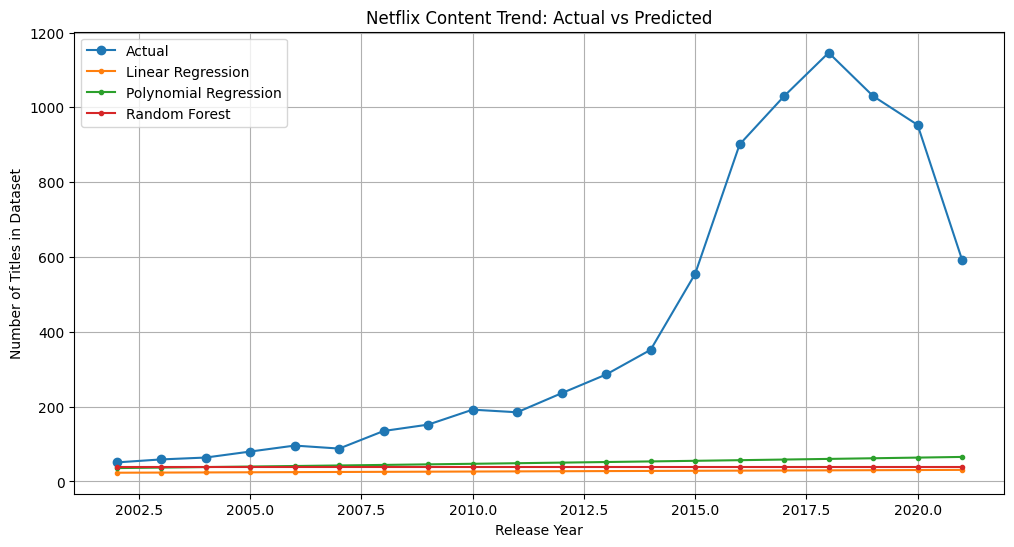

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_data['release_year'],
    y_test,
    marker='o',
    label='Actual'
)

for name, y_pred in predictions.items():
    plt.plot(
        test_data['release_year'],
        y_pred,
        marker='.',
        label=name
    )

plt.title('Netflix Content Trend: Actual vs Predicted')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles in Dataset')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]['Model']
print("Best model based on test MAE:", best_model_name)

best_model = models[best_model_name]
best_model.fit(
    yearly_data[['release_year']],
    yearly_data['content_count']
)

last_year = int(yearly_data['release_year'].max())

future_data = pd.DataFrame({
    'release_year': range(last_year + 1, last_year + 6)
})

future_predictions = best_model.predict(future_data[['release_year']])
future_predictions = np.maximum(future_predictions, 0)

future_data['predicted_content_count'] = np.rint(
    future_predictions
).astype(int)

print("FUTURE FORECAST")
display(future_data)

future_data.to_csv('Netflix_Trend_Forecast.csv', index=False)

Best model based on test MAE: Polynomial Regression
FUTURE FORECAST


,release_year,predicted_content_count
0,2022,619
1,2023,642
2,2024,665
3,2025,689
4,2026,712


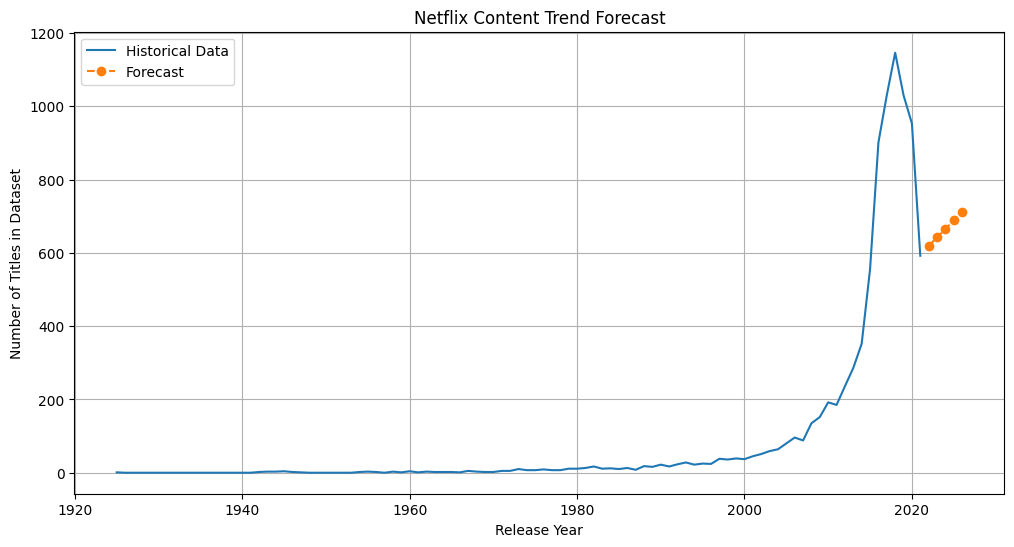

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_data['release_year'],
    yearly_data['content_count'],
    label='Historical Data'
)

plt.plot(
    future_data['release_year'],
    future_data['predicted_content_count'],
    marker='o',
    linestyle='--',
    label='Forecast'
)

plt.title('Netflix Content Trend Forecast')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles in Dataset')
plt.legend()
plt.grid(True)

plt.savefig('Netflix_Trend_Forecast.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

series = yearly_data.copy()

series['release_year'] = series['release_year'].astype(int)

series = series.sort_values('release_year')

series = series.set_index(
    pd.PeriodIndex(series['release_year'], freq='Y')
)['content_count']

split_index = int(len(series) * 0.8)

train_series = series.iloc[:split_index]
test_series = series.iloc[split_index:]

model = ExponentialSmoothing(
    train_series,
    trend='add',
    damped_trend=True,
    seasonal=None,
    initialization_method='estimated'
)

fitted_model = model.fit(optimized=True)

test_predictions = fitted_model.forecast(len(test_series))

test_predictions = np.maximum(test_predictions, 0)

mae = mean_absolute_error(test_series, test_predictions)
rmse = np.sqrt(mean_squared_error(test_series, test_predictions))
r2 = r2_score(test_series, test_predictions)

print("Holt's Exponential Smoothing Results")
print("------------------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

Holt's Exponential Smoothing Results
------------------------------------
MAE: 341.8
RMSE: 501.84
R² Score: -0.7533


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

naive_predictions = np.repeat(
    train_series.iloc[-1],
    len(test_series)
)

mae = mean_absolute_error(test_series, naive_predictions)
rmse = np.sqrt(mean_squared_error(test_series, naive_predictions))
r2 = r2_score(test_series, naive_predictions)

print("Naive Forecasting Results")
print("-------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

Naive Forecasting Results
-------------------------
MAE: 364.15
RMSE: 525.59
R² Score: -0.9231


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

window_size = 5

moving_average_value = train_series.iloc[-window_size:].mean()

moving_average_predictions = np.repeat(
    moving_average_value,
    len(test_series)
)

mae = mean_absolute_error(test_series, moving_average_predictions)
rmse = np.sqrt(mean_squared_error(test_series, moving_average_predictions))
r2 = r2_score(test_series, moving_average_predictions)

print("Moving Average Forecasting Results")
print("-----------------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

Moving Average Forecasting Results
-----------------------------------
MAE: 370.15
RMSE: 529.77
R² Score: -0.9538


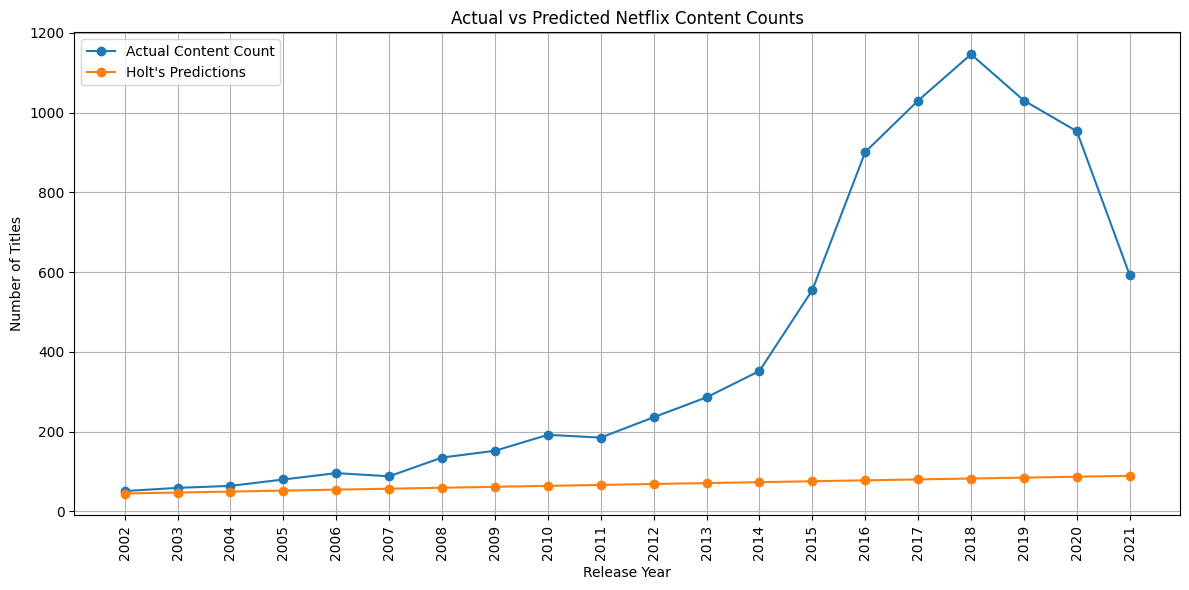

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

plt.plot(
    test_series.index.astype(str),
    test_series.values,
    label='Actual Content Count',
    marker='o'
)

plt.plot(
    test_series.index.astype(str),
    test_predictions,
    label="Holt's Predictions",
    marker='o'
)

plt.title("Actual vs Predicted Netflix Content Counts")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

recent_data = yearly_data[
    yearly_data['release_year'] >= 2000
].copy()

X = recent_data[['release_year']].values
y = recent_data['content_count'].values

split = int(len(recent_data) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)
predictions = np.maximum(predictions, 0)

print("Recent-Years Polynomial Regression")
print("----------------------------------")
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))
print("R² Score:", round(r2_score(y_test, predictions), 4))

Recent-Years Polynomial Regression
----------------------------------
MAE: 301.35
RMSE: 390.07
R² Score: -3.241


In [ ]:
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

recent_data = yearly_data[
    yearly_data['release_year'] >= 2000
].copy()

recent_data = recent_data.sort_values('release_year')

years = recent_data['release_year'].to_numpy()
counts = recent_data['content_count'].to_numpy()

split = int(len(recent_data) * 0.8)

train_years = years[:split]
test_years = years[split:]

y_train = counts[:split]
y_test = counts[split:]

holt_model = ExponentialSmoothing(
    y_train,
    trend='add',
    damped_trend=True,
    initialization_method='estimated'
).fit(optimized=True)

holt_predictions = np.maximum(
    holt_model.forecast(len(y_test)), 0
)

poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

poly_model.fit(train_years.reshape(-1, 1), y_train)

poly_predictions = np.maximum(
    poly_model.predict(test_years.reshape(-1, 1)), 0
)

for name, predictions in [
    ("Holt's Exponential Smoothing", holt_predictions),
    ("Polynomial Regression", poly_predictions)
]:
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))
    print("R²:", round(r2_score(y_test, predictions), 4))


Holt's Exponential Smoothing
MAE: 976.75
RMSE: 1168.83
R²: -37.0785

Polynomial Regression
MAE: 301.35
RMSE: 390.07
R²: -3.241


In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

recent_data = yearly_data[
    yearly_data['release_year'] >= 2000
].copy().sort_values('release_year')

years = recent_data['release_year'].to_numpy()
counts = recent_data['content_count'].to_numpy()

split = int(len(recent_data) * 0.8)

X_train = years[:split].reshape(-1, 1)
X_test = years[split:].reshape(-1, 1)
y_train = counts[:split]
y_test = counts[split:]

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = np.maximum(rf_model.predict(X_test), 0)

print("Recent-Years Random Forest")
print("--------------------------")
print("MAE:", round(mean_absolute_error(y_test, rf_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_predictions)), 2))
print("R²:", round(r2_score(y_test, rf_predictions), 4))

Recent-Years Random Forest
--------------------------
MAE: 384.04
RMSE: 428.21
R²: -4.1109


In [ ]:
comparison = pd.DataFrame({
    'Year': test_years,
    'Actual_Count': y_test,
    'Predicted_Count': np.round(poly_predictions).astype(int)
})

comparison['Absolute_Error'] = abs(
    comparison['Actual_Count'] - comparison['Predicted_Count']
)

print(comparison.to_string(index=False))

 Year  Actual_Count  Predicted_Count  Absolute_Error
 2017        1030.0              801           229.0
 2018        1146.0              927           219.0
 2019        1030.0             1063            33.0
 2020         953.0             1208           255.0
 2021         592.0             1363           771.0


In [ ]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

for degree in [1, 2, 3]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    predictions = np.maximum(model.predict(X_test), 0)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print(f"\nPolynomial Degree: {degree}")
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R²:", round(r2, 4))


Polynomial Degree: 1
MAE: 380.66
RMSE: 417.99
R²: -3.8699

Polynomial Degree: 2
MAE: 301.35
RMSE: 390.07
R²: -3.241

Polynomial Degree: 3
MAE: 745.21
RMSE: 1006.66
R²: -27.2448


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mean_predictions = np.full(
    len(y_test),
    np.mean(y_train)
)

print("Training Mean Baseline")
print("----------------------")
print("MAE:", round(mean_absolute_error(y_test, mean_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, mean_predictions)), 2))
print("R²:", round(r2_score(y_test, mean_predictions), 4))

Training Mean Baseline
----------------------
MAE: 743.49
RMSE: 767.24
R²: -15.4074


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
yearly_data = (
    df.groupby('release_year')
      .size()
      .reset_index(name='content_count')
)

all_years = pd.DataFrame({
    'release_year': range(
        int(yearly_data['release_year'].min()),
        int(yearly_data['release_year'].max()) + 1
    )
})

yearly_data = all_years.merge(
    yearly_data,
    on='release_year',
    how='left'
)

yearly_data['content_count'] = (
    yearly_data['content_count'].fillna(0)
)

yearly_data['release_year'] = (
    yearly_data['release_year'].astype(int)
)

recent_data = yearly_data[
    yearly_data['release_year'] >= 2000
].copy()

recent_data = recent_data.sort_values('release_year')

print("Dataset shape:", recent_data.shape)
print("\nFirst five rows:")
print(recent_data.head())

print("\nLast five rows:")
print(recent_data.tail())

Dataset shape: (22, 2)

First five rows:
    release_year  content_count
75          2000           37.0
76          2001           45.0
77          2002           51.0
78          2003           59.0
79          2004           64.0

Last five rows:
    release_year  content_count
92          2017         1030.0
93          2018         1146.0
94          2019         1030.0
95          2020          953.0
96          2021          592.0


In [ ]:
X = recent_data[['release_year']].to_numpy()
y = recent_data['content_count'].to_numpy()

split = int(len(recent_data) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("Training years:", X_train[0][0], "to", X_train[-1][0])
print("Testing years:", X_test[0][0], "to", X_test[-1][0])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training years: 2000 to 2016
Testing years: 2017 to 2021
Training samples: 17
Testing samples: 5


In [ ]:
model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

model.fit(X_train, y_train)

test_predictions = np.maximum(
    model.predict(X_test),
    0
)

print("Polynomial Regression model trained successfully.")

Polynomial Regression model trained successfully.


In [ ]:
mae = mean_absolute_error(
    y_test,
    test_predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

r2 = r2_score(
    y_test,
    test_predictions
)

print("MODEL EVALUATION")
print("================")
print("Model: Polynomial Regression, Degree 2")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

MODEL EVALUATION
Model: Polynomial Regression, Degree 2
MAE: 301.35
RMSE: 390.07
R² Score: -3.241


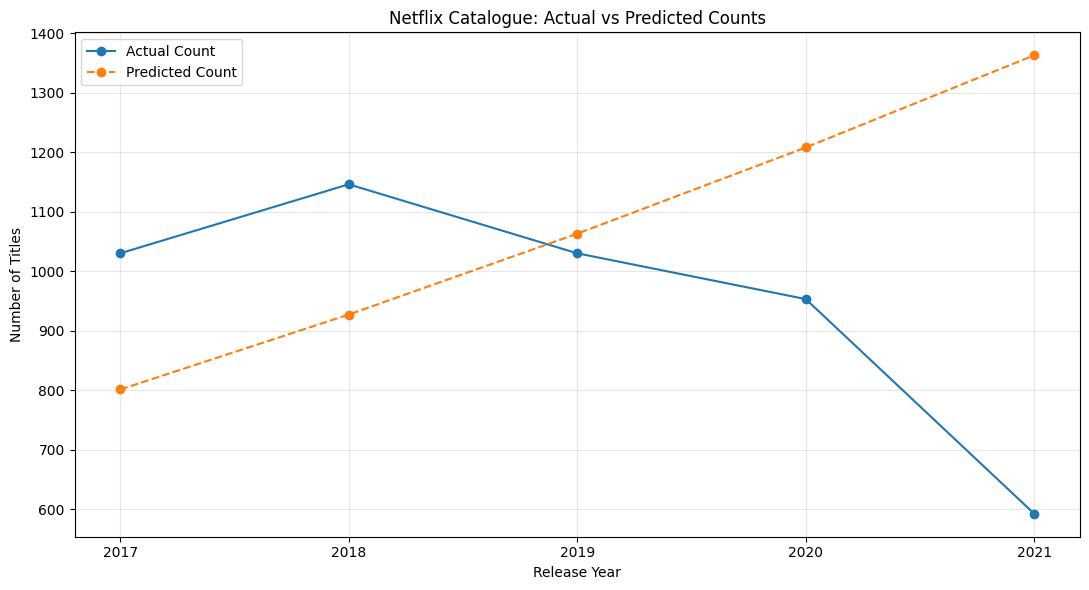

 Year  Actual_Count  Predicted_Count  Absolute_Error
 2017        1030.0              801           229.0
 2018        1146.0              927           219.0
 2019        1030.0             1063            33.0
 2020         953.0             1208           255.0
 2021         592.0             1363           771.0


In [ ]:
comparison_df = pd.DataFrame({
    'Year': X_test.flatten().astype(int),
    'Actual_Count': y_test,
    'Predicted_Count': np.round(
        test_predictions
    ).astype(int)
})

comparison_df['Absolute_Error'] = abs(
    comparison_df['Actual_Count']
    - comparison_df['Predicted_Count']
)

plt.figure(figsize=(11, 6))

plt.plot(
    comparison_df['Year'],
    comparison_df['Actual_Count'],
    marker='o',
    label='Actual Count'
)

plt.plot(
    comparison_df['Year'],
    comparison_df['Predicted_Count'],
    marker='o',
    linestyle='--',
    label='Predicted Count'
)

plt.title('Netflix Catalogue: Actual vs Predicted Counts')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.xticks(comparison_df['Year'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    'Netflix_Actual_vs_Predicted.png',
    dpi=300
)

plt.show()

print(comparison_df.to_string(index=False))

In [ ]:
X_all = recent_data[['release_year']].to_numpy()
y_all = recent_data['content_count'].to_numpy()

final_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

final_model.fit(X_all, y_all)

future_years = np.arange(
    2022, 2027
).reshape(-1, 1)

future_predictions = np.maximum(
    final_model.predict(future_years),
    0
)

forecast_df = pd.DataFrame({
    'Year': future_years.flatten(),
    'Forecast_Content_Count': np.round(
        future_predictions
    ).astype(int)
})

print("EXPLORATORY FORECAST: 2022–2026")
print("================================")
print(forecast_df.to_string(index=False))

EXPLORATORY FORECAST: 2022–2026
 Year  Forecast_Content_Count
 2022                    1192
 2023                    1303
 2024                    1419
 2025                    1540
 2026                    1666


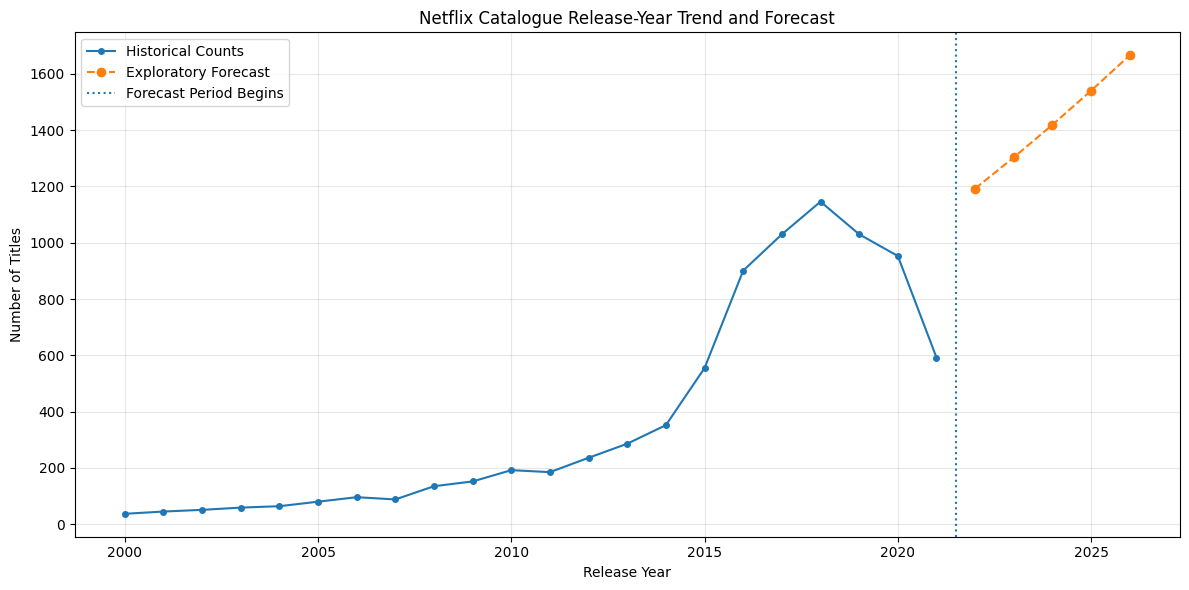

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    X_all.flatten(),
    y_all,
    marker='o',
    markersize=4,
    label='Historical Counts'
)

plt.plot(
    future_years.flatten(),
    future_predictions,
    marker='o',
    linestyle='--',
    label='Exploratory Forecast'
)

plt.axvline(
    x=2021.5,
    linestyle=':',
    label='Forecast Period Begins'
)

plt.title('Netflix Catalogue Release-Year Trend and Forecast')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    'Netflix_Trend_Forecast.png',
    dpi=300
)

plt.show()

In [ ]:
comparison_df.to_csv(
    'Netflix_Model_Evaluation.csv',
    index=False
)

forecast_df.to_csv(
    'Netflix_Trend_Forecast_2022_2026.csv',
    index=False
)

print("Files created:")
print("1. Netflix_Actual_vs_Predicted.png")
print("2. Netflix_Trend_Forecast.png")
print("3. Netflix_Model_Evaluation.csv")
print("4. Netflix_Trend_Forecast_2022_2026.csv")

Files created:
1. Netflix_Actual_vs_Predicted.png
2. Netflix_Trend_Forecast.png
3. Netflix_Model_Evaluation.csv
4. Netflix_Trend_Forecast_2022_2026.csv


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

comparison_df = pd.DataFrame({
    "Year": X_test.flatten().astype(int),
    "Actual_Count": y_test.astype(int),
    "Polynomial_Prediction": np.round(test_predictions).astype(int)
})

count_by_year = dict(
    zip(recent_data["release_year"], recent_data["content_count"])
)

comparison_df["Previous_Year_Baseline"] = comparison_df["Year"].apply(
    lambda year: int(count_by_year[year - 1])
)

poly_mae = mean_absolute_error(
    comparison_df["Actual_Count"],
    comparison_df["Polynomial_Prediction"]
)
poly_rmse = np.sqrt(mean_squared_error(
    comparison_df["Actual_Count"],
    comparison_df["Polynomial_Prediction"]
))
poly_r2 = r2_score(
    comparison_df["Actual_Count"],
    comparison_df["Polynomial_Prediction"]
)

baseline_mae = mean_absolute_error(
    comparison_df["Actual_Count"],
    comparison_df["Previous_Year_Baseline"]
)
baseline_rmse = np.sqrt(mean_squared_error(
    comparison_df["Actual_Count"],
    comparison_df["Previous_Year_Baseline"]
))
baseline_r2 = r2_score(
    comparison_df["Actual_Count"],
    comparison_df["Previous_Year_Baseline"]
)

print("ACTUAL vs PREDICTED COUNTS")
display(comparison_df)

results = pd.DataFrame({
    "Model": ["Polynomial Regression (Degree 2)", "Previous-Year Baseline"],
    "MAE": [round(poly_mae, 2), round(baseline_mae, 2)],
    "RMSE": [round(poly_rmse, 2), round(baseline_rmse, 2)],
    "R2 Score": [round(poly_r2, 3), round(baseline_r2, 3)]
})

print("\nMODEL COMPARISON")
display(results)

if poly_mae < baseline_mae:
    print("Polynomial Regression has lower MAE on this test period.")
elif poly_mae > baseline_mae:
    print("Previous-Year Baseline has lower MAE on this test period.")
else:
    print("Both models have the same MAE on this test period.")

ACTUAL vs PREDICTED COUNTS


,Year,Actual_Count,Polynomial_Prediction,Previous_Year_Baseline
0,2017,1030,801,901
1,2018,1146,927,1030
2,2019,1030,1063,1146
3,2020,953,1208,1030
4,2021,592,1363,953



MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Polynomial Regression (Degree 2),301.4,390.12,-3.242
1,Previous-Year Baseline,159.8,189.63,-0.002


Previous-Year Baseline has lower MAE on this test period.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = recent_data.sort_values("release_year").reset_index(drop=True)

years = data["release_year"].to_numpy(dtype=int)
counts = data["content_count"].to_numpy(dtype=float)

test_years = [2017, 2018, 2019, 2020, 2021]

results = []

for year in test_years:

    train_mask = years < year
    X_train = years[train_mask].reshape(-1, 1)
    y_train = counts[train_mask]

    actual = counts[years == year][0]
    previous_year_count = counts[years == year - 1][0]

    previous_prediction = previous_year_count

    last_three_counts = counts[
        (years >= year - 3) & (years < year)
    ]
    moving_average_prediction = np.mean(last_three_counts)

    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)
    linear_prediction = linear_model.predict([[year]])[0]

    poly = PolynomialFeatures(degree=2, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)

    poly_model = LinearRegression()
    poly_model.fit(X_train_poly, y_train)

    X_year_poly = poly.transform([[year]])
    polynomial_prediction = poly_model.predict(X_year_poly)[0]

    results.append({
        "Year": year,
        "Actual": actual,
        "Previous_Year_Baseline": previous_prediction,
        "Moving_Average_3Y": moving_average_prediction,
        "Linear_Regression": linear_prediction,
        "Polynomial_Degree_2": polynomial_prediction
    })

comparison = pd.DataFrame(results)

prediction_columns = [
    "Previous_Year_Baseline",
    "Moving_Average_3Y",
    "Linear_Regression",
    "Polynomial_Degree_2"
]

for col in prediction_columns:
    comparison[col] = comparison[col].round().astype(int)

print("ROLLING ONE-YEAR-AHEAD PREDICTIONS")
display(comparison)

metric_results = []

for model_name in prediction_columns:
    actual_values = comparison["Actual"].to_numpy()
    predicted_values = comparison[model_name].to_numpy()

    mae = mean_absolute_error(actual_values, predicted_values)
    rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))
    r2 = r2_score(actual_values, predicted_values)

    metric_results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2_Score": round(r2, 3)
    })

metrics_df = pd.DataFrame(metric_results)
metrics_df = metrics_df.sort_values("MAE").reset_index(drop=True)

print("\nMODEL PERFORMANCE — LOWER MAE AND RMSE ARE BETTER")
display(metrics_df)

best_model = metrics_df.iloc[0]

print("\nBEST MODEL BY MAE:", best_model["Model"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("R2 Score:", best_model["R2_Score"])

ROLLING ONE-YEAR-AHEAD PREDICTIONS


,Year,Actual,Previous_Year_Baseline,Moving_Average_3Y,Linear_Regression,Polynomial_Degree_2
0,2017,1030.0,901,603,531,801
1,2018,1146.0,1030,829,678,1042
2,2019,1030.0,1146,1026,821,1251
3,2020,953.0,1030,1069,915,1333
4,2021,592.0,953,1043,977,1344



MODEL PERFORMANCE — LOWER MAE AND RMSE ARE BETTER


,Model,MAE,RMSE,R2_Score
0,Previous_Year_Baseline,159.8,189.63,-0.002
1,Moving_Average_3Y,263.0,316.13,-1.786
2,Linear_Regression,319.8,363.70,-2.687
3,Polynomial_Degree_2,337.2,405.46,-3.582



BEST MODEL BY MAE: Previous_Year_Baseline
MAE: 159.8
RMSE: 189.63
R2 Score: -0.002


In [ ]:
import numpy as np
import pandas as pd

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    ExponentialSmoothing
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = recent_data.sort_values("release_year").reset_index(drop=True)

years = data["release_year"].to_numpy(dtype=int)
counts = data["content_count"].to_numpy(dtype=float)

test_years = [2017, 2018, 2019, 2020, 2021]

predictions = []

for year in test_years:

    train_counts = counts[years < year]

    actual = counts[years == year][0]

    previous_year_prediction = train_counts[-1]

    ses_model = SimpleExpSmoothing(
        train_counts,
        initialization_method="estimated"
    )
    ses_fit = ses_model.fit(optimized=True)
    ses_prediction = ses_fit.forecast(1)[0]

    holt_model = ExponentialSmoothing(
        train_counts,
        trend="add",
        damped_trend=True,
        initialization_method="estimated"
    )
    holt_fit = holt_model.fit(optimized=True)
    holt_prediction = holt_fit.forecast(1)[0]

    predictions.append({
        "Year": year,
        "Actual": actual,
        "Previous_Year_Baseline": previous_year_prediction,
        "Simple_Exponential_Smoothing": ses_prediction,
        "Holt_Damped_Trend": holt_prediction
    })

prediction_df = pd.DataFrame(predictions)

print("ROLLING ONE-YEAR-AHEAD PREDICTIONS")
display(prediction_df.round(2))

model_columns = [
    "Previous_Year_Baseline",
    "Simple_Exponential_Smoothing",
    "Holt_Damped_Trend"
]

actual_values = prediction_df["Actual"].to_numpy()

metrics = []

for model_name in model_columns:

    predicted_values = prediction_df[model_name].to_numpy()

    mae = mean_absolute_error(actual_values, predicted_values)
    rmse = np.sqrt(
        mean_squared_error(actual_values, predicted_values)
    )
    r2 = r2_score(actual_values, predicted_values)

    metrics.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2_Score": round(r2, 3)
    })

metrics_df = pd.DataFrame(metrics)
metrics_df = metrics_df.sort_values("MAE").reset_index(drop=True)

print("\nMODEL PERFORMANCE — LOWER MAE AND RMSE ARE BETTER")
display(metrics_df)

print("\nBEST MODEL BY MAE:", metrics_df.iloc[0]["Model"])
print("MAE:", metrics_df.iloc[0]["MAE"])
print("RMSE:", metrics_df.iloc[0]["RMSE"])
print("R2 Score:", metrics_df.iloc[0]["R2_Score"])

ROLLING ONE-YEAR-AHEAD PREDICTIONS


,Year,Actual,Previous_Year_Baseline,Simple_Exponential_Smoothing,Holt_Damped_Trend
0,2017,1030.0,901.0,901.0,1245.27
1,2018,1146.0,1030.0,1030.0,1212.27
2,2019,1030.0,1146.0,1146.0,1238.51
3,2020,953.0,1030.0,1030.0,952.04
4,2021,592.0,953.0,953.0,886.67



MODEL PERFORMANCE — LOWER MAE AND RMSE ARE BETTER


,Model,MAE,RMSE,R2_Score
0,Holt_Damped_Trend,157.14,190.28,-0.009
1,Previous_Year_Baseline,159.80,189.63,-0.002
2,Simple_Exponential_Smoothing,159.80,189.63,-0.002



BEST MODEL BY MAE: Holt_Damped_Trend
MAE: 157.14
RMSE: 190.28
R2 Score: -0.009


In [ ]:

print("Dataset columns:")
print(df.columns.tolist())

if "date_added" in df.columns:
    print("\nMissing date_added values:")
    print(df["date_added"].isna().sum())

    print("\nSample date_added values:")
    print(df["date_added"].dropna().head(10))
else:
    print("\ndate_added column is not available.")

Dataset columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Missing date_added values:
0

Sample date_added values:
0    9/25/2021
1    9/24/2021
2    9/24/2021
3    9/22/2021
4    9/24/2021
5    9/24/2021
6    9/24/2021
7     5/1/2021
8    9/23/2021
9     5/1/2021
Name: date_added, dtype: object


Netflix Catalogue Addition Dataset
Dataset shape: (14, 2)


,added_year,titles_added
0,2008,2
1,2009,2
2,2010,1
3,2011,13
4,2012,3
5,2013,11
6,2014,24
7,2015,82
8,2016,426
9,2017,1185


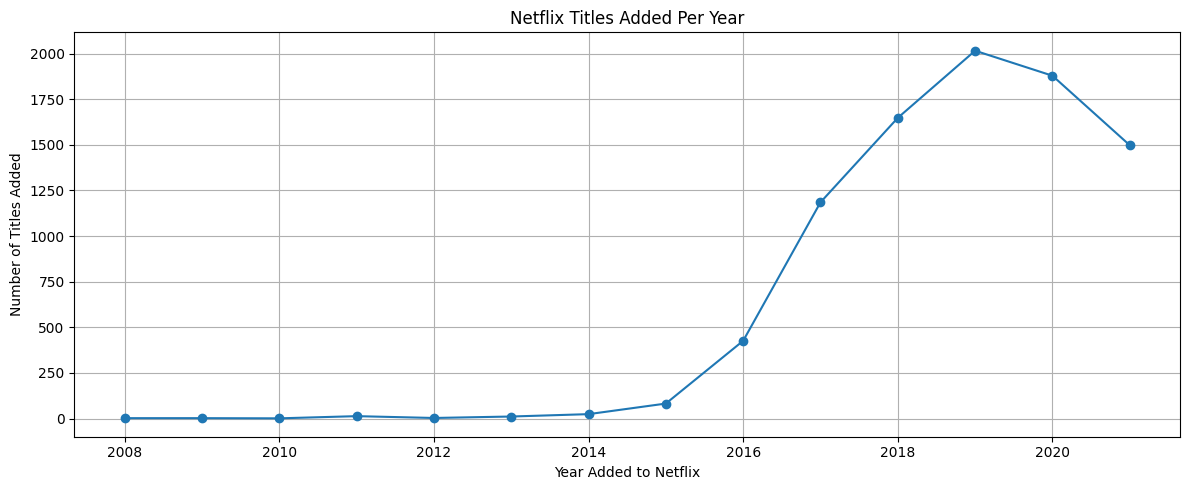

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df["date_added"] = pd.to_datetime(
    df["date_added"],
    format="mixed",
    errors="coerce"
)

df["added_year"] = df["date_added"].dt.year

addition_data = (
    df.groupby("added_year")
      .size()
      .reset_index(name="titles_added")
)

addition_data = addition_data.sort_values("added_year")

print("Netflix Catalogue Addition Dataset")
print("Dataset shape:", addition_data.shape)
display(addition_data)

plt.figure(figsize=(12, 5))
plt.plot(
    addition_data["added_year"],
    addition_data["titles_added"],
    marker="o"
)

plt.title("Netflix Titles Added Per Year")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles Added")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = addition_data.sort_values("added_year").copy()

all_years = pd.DataFrame({
    "added_year": range(
        int(data["added_year"].min()),
        int(data["added_year"].max()) + 1
    )
})

data = all_years.merge(data, on="added_year", how="left")
data["titles_added"] = data["titles_added"].fillna(0)

years = data["added_year"].to_numpy(dtype=int)
counts = data["titles_added"].to_numpy(dtype=float)

train_mask = years <= 2017
test_mask = years >= 2018

train_counts = counts[train_mask]
test_years = years[test_mask]
actual_values = counts[test_mask]

previous_predictions = np.repeat(train_counts[-1], len(test_years))

moving_predictions = []

for year in test_years:
    previous_counts = counts[years < year][-3:]
    moving_predictions.append(np.mean(previous_counts))

moving_predictions = np.array(moving_predictions)

holt_model = ExponentialSmoothing(
    train_counts,
    trend="add",
    damped_trend=True,
    initialization_method="estimated"
)

holt_fit = holt_model.fit(optimized=True)
holt_predictions = holt_fit.forecast(len(test_years))

comparison = pd.DataFrame({
    "Year": test_years,
    "Actual": actual_values.astype(int),
    "Previous_Year_Baseline": previous_predictions.astype(int),
    "Moving_Average_3Y": np.round(moving_predictions).astype(int),
    "Holt_Damped_Trend": np.round(holt_predictions).astype(int)
})

print("FORECAST COMPARISON")
display(comparison)

model_predictions = {
    "Previous-Year Baseline": previous_predictions,
    "3-Year Moving Average": moving_predictions,
    "Holt's Damped Trend": holt_predictions
}

metrics = []

for model_name, predictions in model_predictions.items():
    mae = mean_absolute_error(actual_values, predictions)
    rmse = np.sqrt(mean_squared_error(actual_values, predictions))
    r2 = r2_score(actual_values, predictions)

    metrics.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2_Score": round(r2, 3)
    })

metrics_df = pd.DataFrame(metrics).sort_values("MAE").reset_index(drop=True)

print("\nMODEL PERFORMANCE — LOWER MAE AND RMSE ARE BETTER")
display(metrics_df)

print("\nBest model by MAE:", metrics_df.iloc[0]["Model"])

FORECAST COMPARISON


,Year,Actual,Previous_Year_Baseline,Moving_Average_3Y,Holt_Damped_Trend
0,2018,1648,1185,564,1940
1,2019,2016,1185,1086,2692
2,2020,1879,1185,1616,3439
3,2021,1498,1185,1848,4183



MODEL PERFORMANCE — LOWER MAE AND RMSE ARE BETTER


,Model,MAE,RMSE,R2_Score
0,Previous-Year Baseline,575.25,609.21,-8.227
1,3-Year Moving Average,656.42,746.64,-12.860
2,Holt's Damped Trend,1303.35,1595.85,-62.318



Best model by MAE: Previous-Year Baseline


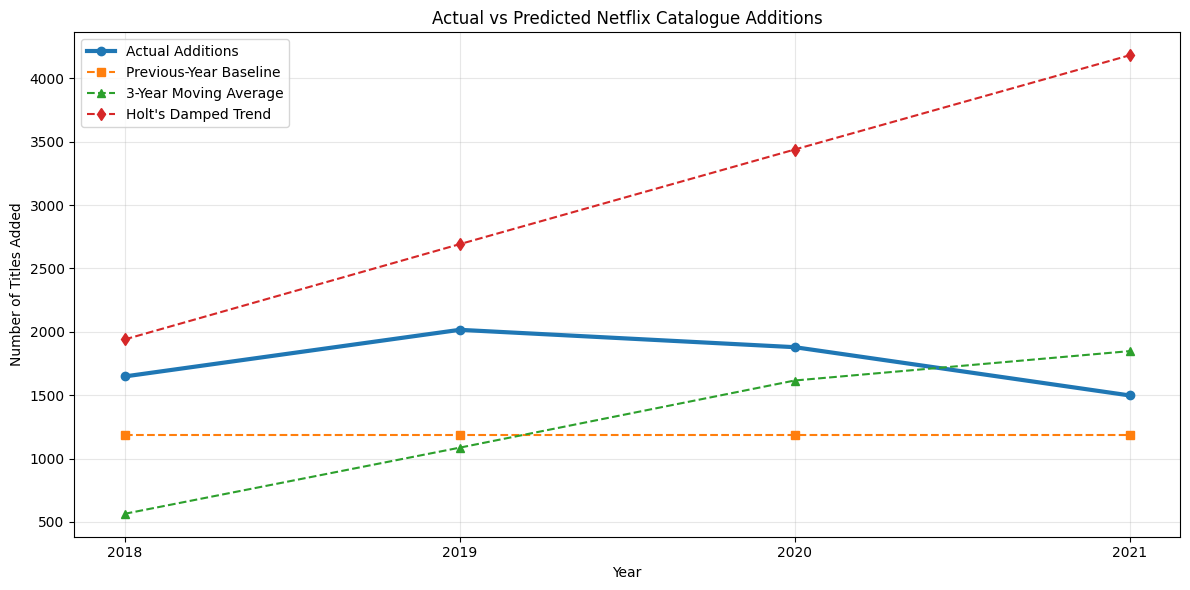

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    comparison["Year"],
    comparison["Actual"],
    marker="o",
    linewidth=3,
    label="Actual Additions"
)

plt.plot(
    comparison["Year"],
    comparison["Previous_Year_Baseline"],
    marker="s",
    linestyle="--",
    label="Previous-Year Baseline"
)

plt.plot(
    comparison["Year"],
    comparison["Moving_Average_3Y"],
    marker="^",
    linestyle="--",
    label="3-Year Moving Average"
)

plt.plot(
    comparison["Year"],
    comparison["Holt_Damped_Trend"],
    marker="d",
    linestyle="--",
    label="Holt's Damped Trend"
)

plt.title("Actual vs Predicted Netflix Catalogue Additions")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")
plt.xticks(comparison["Year"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("Netflix_Additions_Model_Comparison.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

model_results = []

model_results.append({
    "Model": "Previous-Year Baseline",
    "MAE": mean_absolute_error(actual_values, previous_predictions),
    "RMSE": np.sqrt(mean_squared_error(actual_values, previous_predictions))
})

configurations = [
    {"trend": None, "damped_trend": False, "name": "Level Only"},
    {"trend": "add", "damped_trend": False, "name": "Holt Linear Trend"},
    {"trend": "add", "damped_trend": True, "name": "Holt Damped Trend"}
]

for config in configurations:
    model = ExponentialSmoothing(
        train_counts,
        trend=config["trend"],
        damped_trend=config["damped_trend"],
        initialization_method="estimated"
    )

    fitted_model = model.fit(optimized=True)
    predictions = fitted_model.forecast(len(actual_values))

    model_results.append({
        "Model": config["name"],
        "MAE": mean_absolute_error(actual_values, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual_values, predictions))
    })

results_df = pd.DataFrame(model_results)
results_df[["MAE", "RMSE"]] = results_df[["MAE", "RMSE"]].round(2)
results_df = results_df.sort_values("MAE").reset_index(drop=True)

print("HOLT MODEL COMPARISON")
display(results_df)

HOLT MODEL COMPARISON


,Model,MAE,RMSE
0,Previous-Year Baseline,575.25,609.21
1,Level Only,575.25,609.21
2,Holt Damped Trend,1303.35,1595.85
3,Holt Linear Trend,1322.25,1618.66


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

data = addition_data.sort_values("added_year").copy()

train_data = data[
    (data["added_year"] >= 2014) &
    (data["added_year"] <= 2017)
]

test_data = data[
    (data["added_year"] >= 2018) &
    (data["added_year"] <= 2021)
]

X_train = train_data[["added_year"]]
y_train = train_data["titles_added"]

X_test = test_data[["added_year"]]
y_test = test_data["titles_added"]

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

comparison_recent = pd.DataFrame({
    "Year": X_test["added_year"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": np.round(predictions).astype(int)
})

print("RECENT-YEARS LINEAR REGRESSION")
display(comparison_recent)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

RECENT-YEARS LINEAR REGRESSION


,Year,Actual,Predicted
0,2018,1648,1386
1,2019,2016,1769
2,2020,1879,2151
3,2021,1498,2534


MAE: 454.45
RMSE: 565.13
